# Soft-constrained MPC with OSQP slack penalties

This notebook shows how to use the slack penalties of the modified OSQP solver in a model predictive controller (MPC). A soft constraint relaxes

$$\ell \le Ax \le u \qquad\text{to}\qquad \ell \le Ax + \xi \le u,$$

and adds a penalty $\Phi(\xi)$ on the slack $\xi$ to the objective. The solver eliminates $\xi$, so a soft QP has the **same size** as the hard QP. You only add one call, `setup_penalty`, after `setup`.

The example is a cart (a double integrator) that must stay below a position limit. We look at:

1. a disturbance that makes the hard-constrained MPC **infeasible**, while the soft MPC recovers;
2. how the **penalty choice** shapes the violation: quadratic vs. $\ell_1$ (an exact penalty);
3. **online updates** of the bounds and the penalty weights, without a new setup.

The notebook only needs `osqp` (the modified version from this repo), `numpy`, `scipy`, and `matplotlib`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import osqp
from scipy import sparse

%config InlineBackend.figure_format = "retina"

PT = osqp.PenaltyType  # OSQP_PENALTY_NONE (hard), _L1L2, _HUBER, _NORM2, _NORMINF

## The MPC problem

The cart has position $p$ and velocity $v$, and we control its acceleration $a$:

$$x_{k+1} = \begin{bmatrix}1 & \Delta t\\ 0 & 1\end{bmatrix} x_k + \begin{bmatrix}\Delta t^2/2\\ \Delta t\end{bmatrix} a_k, \qquad x = (p, v).$$

Over a horizon of $N$ steps, the MPC tracks a reference position $p_\mathrm{ref}$, keeps the position below $p_{\max} = 1$ (the constraint we will soften), and limits the acceleration to $|a_k| \le a_{\max}$ (a physical limit, which stays hard):

$$
\begin{aligned}
\min_{x, a}\quad & \sum_{k=0}^{N} (x_k - x_\mathrm{ref})^\top Q (x_k - x_\mathrm{ref}) + \sum_{k=0}^{N-1} R\, a_k^2 \\
\text{s.t.}\quad & x_0 = x_\mathrm{init},\quad x_{k+1} = A_d x_k + B_d a_k, \\
& -p_{\max} \le p_k \le p_{\max}, \quad -a_{\max} \le a_k \le a_{\max}.
\end{aligned}
$$

We stack all states and inputs into one decision vector $z = (x_0, \dots, x_N, a_0, \dots, a_{N-1})$ and build the sparse QP in the form OSQP expects, $\min \tfrac12 z^\top P z + q^\top z$ s.t. $l \le A z \le u$.

In [2]:
dt, N = 0.1, 20
Ad = np.array([[1.0, dt], [0.0, 1.0]])
Bd = np.array([[0.5 * dt**2], [dt]])
nx, nu = 2, 1
Q = np.diag([10.0, 0.1])
R = np.array([[0.1]])
p_max, a_max = 1.0, 1.0

# Objective
P = sparse.block_diag([sparse.kron(sparse.eye(N + 1), Q), sparse.kron(sparse.eye(N), R)], format="csc")


def linear_cost(p_ref):
    x_ref = np.array([p_ref, 0.0])
    return np.concatenate([np.tile(-Q @ x_ref, N + 1), np.zeros(N * nu)])


# Constraints: dynamics (with the initial state), position, acceleration
A_dyn = sparse.hstack(
    [
        sparse.kron(sparse.eye(N + 1), -sparse.eye(nx)) + sparse.kron(sparse.eye(N + 1, k=-1), Ad),
        sparse.kron(sparse.vstack([sparse.csc_matrix((1, N)), sparse.eye(N)]), Bd),
    ]
)
A_pos = sparse.hstack([sparse.kron(sparse.eye(N + 1), [[1.0, 0.0]]), sparse.csc_matrix((N + 1, N * nu))])
A_acc = sparse.hstack([sparse.csc_matrix((N * nu, (N + 1) * nx)), sparse.eye(N * nu)])
A = sparse.vstack([A_dyn, A_pos, A_acc], format="csc")
m = A.shape[0]

# Row indices of the position constraints, the ones we will soften
pos_rows = np.arange((N + 1) * nx, (N + 1) * nx + N + 1)


def bounds(x_init):
    dyn = np.concatenate([-x_init, np.zeros(N * nx)])
    l = np.concatenate([dyn, np.full(N + 1, -p_max), np.full(N * nu, -a_max)])
    u = np.concatenate([dyn, np.full(N + 1, p_max), np.full(N * nu, a_max)])
    return l, u


print(f"QP with {P.shape[0]} variables and {m} constraints")

QP with 62 variables and 83 constraints


## Setting up hard and soft controllers

A soft controller is set up exactly like a hard one, followed by `setup_penalty`. Its arguments are given per constraint row:

- `penalty_type`: the penalty of each row, `OSQP_PENALTY_NONE` for hard rows;
- `alpha1`, `alpha2`, `delta`: the penalty weights. For `L1L2`, $\phi(\xi_i) = \alpha_1|\xi_i| + \tfrac{\alpha_2}{2}\xi_i^2$, which covers the quadratic ($\alpha_1 = 0$), $\ell_1$ ($\alpha_2 = 0$), and elastic-net penalties. For `HUBER`, $\alpha_1$ scales a Huber function with threshold $\delta$.

Here we soften only the position rows. The dynamics and the acceleration limits stay hard.

In [3]:
SETTINGS = dict(eps_abs=1e-5, eps_rel=1e-5, polishing=False, verbose=False)


def controller(penalty_type=None, alpha1=0.0, alpha2=0.0, delta=0.0, p_ref=0.9):
    solver = osqp.OSQP()
    l, u = bounds(np.zeros(nx))
    solver.setup(P, linear_cost(p_ref), A, l, u, **SETTINGS)
    if penalty_type is not None:
        types = np.full(m, PT.OSQP_PENALTY_NONE)
        types[pos_rows] = penalty_type
        weights = {}
        for name, value in (("alpha1", alpha1), ("alpha2", alpha2), ("delta", delta)):
            weights[name] = np.zeros(m)
            weights[name][pos_rows] = value
        solver.setup_penalty(types, **weights)
    return solver

## Closed-loop simulation

At every step, the controller only needs to know the current state. It enters the QP through the bounds of the initial-state constraint, so we pass it with `update(l=..., u=...)`. The matrix factorization and the penalties are kept, and OSQP warm-starts from the previous solution.

At $t = 2\,$s, a disturbance kicks the cart towards the limit.

In [4]:
def simulate(solver, steps=60, kick_step=20, kick=0.6):
    x = np.zeros(nx)
    states, inputs = [x], []
    for k in range(steps):
        if k == kick_step:
            x = x + np.array([0.0, kick])
        l, u = bounds(x)
        solver.update(l=l, u=u)
        result = solver.solve(raise_error=False)
        if result.info.status != "solved":
            print(f"t = {k * dt:.1f} s: {result.info.status}, the controller fails")
            break
        a = result.x[(N + 1) * nx]  # apply the first input
        x = Ad @ x + Bd[:, 0] * a
        states.append(x)
        inputs.append(a)
    return np.array(states), np.array(inputs)

### 1. Hard constraints break, soft constraints recover

After the kick, the cart is too fast to stop before $p_{\max}$, even when it brakes as hard as it can. The hard-constrained QP has no solution, and the controller has nothing to apply. With soft constraints, the controller still returns the best possible input: it brakes and returns below the limit as quickly as the penalty asks for.

t = 2.0 s: primal infeasible, the controller fails


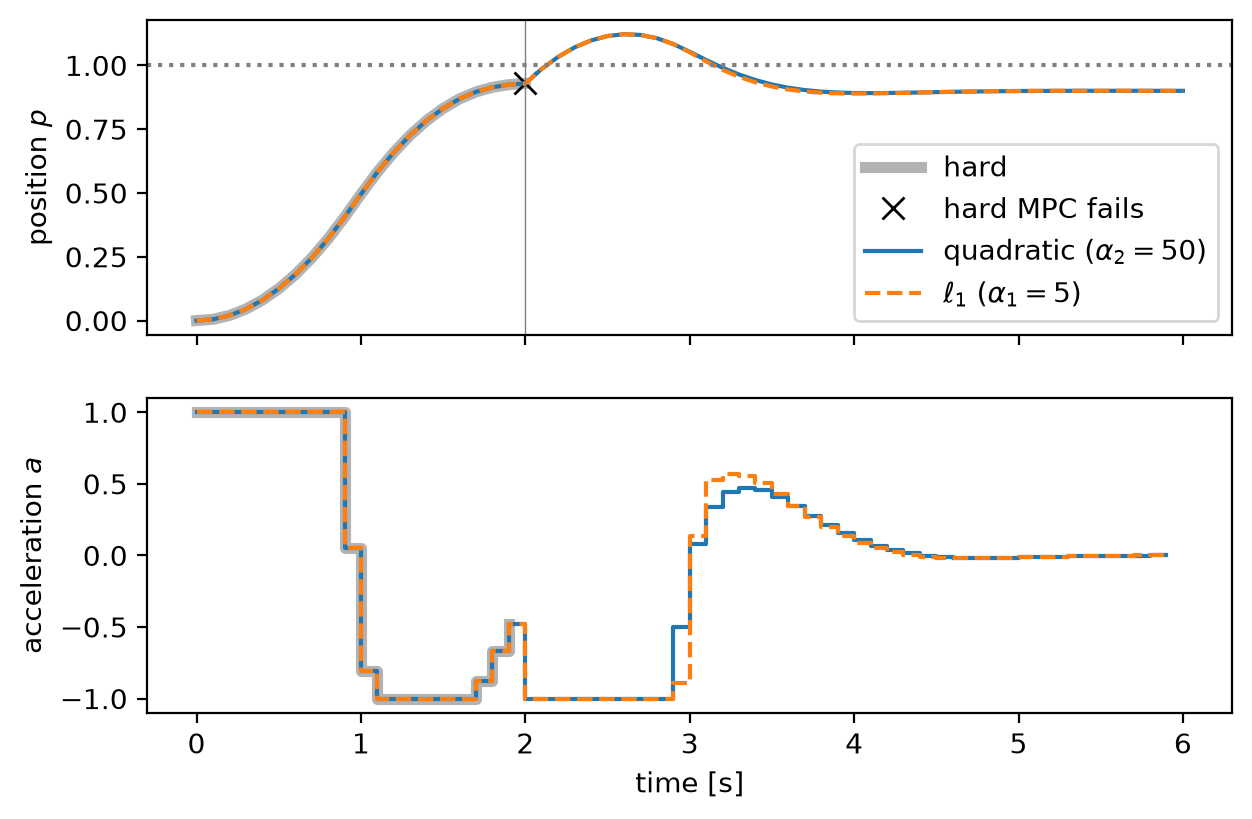

In [5]:
runs = {  # name: (controller, plot style)
    "hard": (controller(), dict(color="0.7", linewidth=4)),
    r"quadratic ($\alpha_2 = 50$)": (controller(PT.OSQP_PENALTY_L1L2, alpha2=50.0), dict(color="C0")),
    r"$\ell_1$ ($\alpha_1 = 5$)": (controller(PT.OSQP_PENALTY_L1L2, alpha1=5.0), dict(color="C1", linestyle="--")),
}

fig, (ax_p, ax_a) = plt.subplots(2, 1, figsize=(7, 4.5), sharex=True)
for name, (solver, style) in runs.items():
    x, a = simulate(solver)
    ax_p.plot(np.arange(len(x)) * dt, x[:, 0], label=name, **style)
    ax_a.step(np.arange(len(a)) * dt, a, where="post", **style)
    if name == "hard":
        ax_p.plot((len(x) - 1) * dt, x[-1, 0], "kx", markersize=8, label="hard MPC fails")
ax_p.axhline(p_max, color="gray", linestyle=":")
ax_p.axvline(2.0, color="gray", linewidth=0.5)
ax_p.set_ylabel("position $p$")
ax_p.legend()
ax_a.set_ylabel("acceleration $a$")
ax_a.set_xlabel("time [s]")
plt.show()

### 2. The penalty shapes the violation

Now let the reference ask for $p_\mathrm{ref} = 1.1$, beyond the limit, with no disturbance. Staying at the limit costs tracking error, so the controller weighs it against the penalty:

- the **quadratic** penalty is cheap for small violations, so the cart settles slightly *above* the limit, at the point where both costs balance;
- the **$\ell_1$** penalty is an *exact* penalty: once its weight exceeds the constraint's Lagrange multiplier, the solution is exactly the hard-constrained one, and the limit holds whenever it can be held.

`solver.slack(x)` returns the slack $\xi$ of every row at the solution, so we can read off the predicted violation directly.

quadratic: final position 1.0167, largest predicted slack 1.7e-02
l1       : final position 1.0000, largest predicted slack 2.4e-06


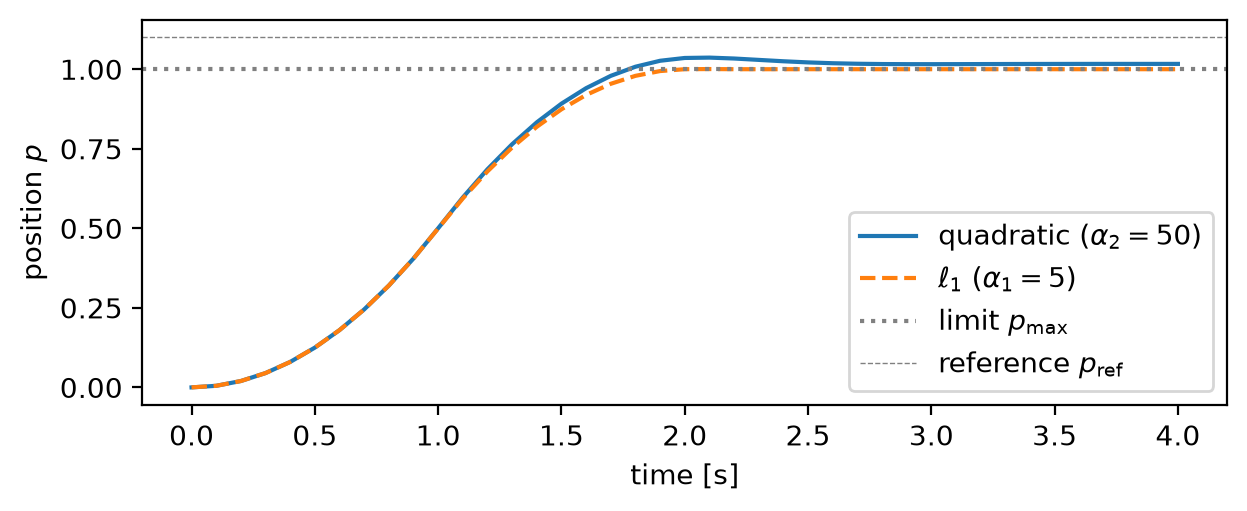

In [6]:
plt.figure(figsize=(7, 2.5))
for name, label, kwargs, style in [
    ("quadratic", r"quadratic ($\alpha_2 = 50$)", dict(alpha2=50.0), dict(color="C0")),
    ("l1", r"$\ell_1$ ($\alpha_1 = 5$)", dict(alpha1=5.0), dict(color="C1", linestyle="--")),
]:
    solver = controller(PT.OSQP_PENALTY_L1L2, p_ref=1.1, **kwargs)
    x, a = simulate(solver, steps=40, kick=0.0)
    xi = solver.slack(solver.solve().x)[pos_rows]
    print(f"{name:9s}: final position {x[-1, 0]:.4f}, largest predicted slack {np.abs(xi).max():.1e}")
    plt.plot(np.arange(len(x)) * dt, x[:, 0], label=label, **style)
plt.axhline(p_max, color="gray", linestyle=":", label=r"limit $p_{\max}$")
plt.axhline(1.1, color="gray", linestyle="--", linewidth=0.5, label=r"reference $p_\mathrm{ref}$")
plt.xlabel("time [s]")
plt.ylabel("position $p$")
plt.legend()
plt.show()

### 3. Updating the penalty online

Penalty weights can be changed between solves with `update_penalty_params`, again without a new setup. Lowering the $\ell_1$ weight below the multiplier makes the violation affordable, and the cart moves past the limit towards its reference. (The penalty *types* can be changed with `update_penalty_types`.)

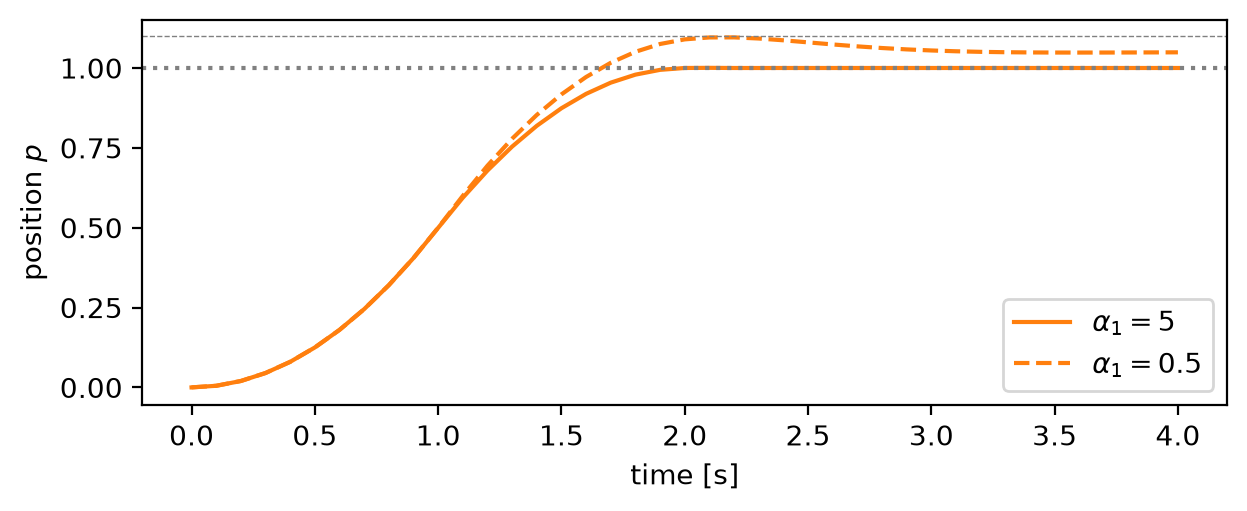

In [7]:
solver = controller(PT.OSQP_PENALTY_L1L2, alpha1=5.0, p_ref=1.1)
x_strict, _ = simulate(solver, steps=40, kick=0.0)

alpha1 = np.zeros(m)
alpha1[pos_rows] = 0.5
solver.update_penalty_params(alpha1=alpha1)
x_relaxed, _ = simulate(solver, steps=40, kick=0.0)

t = np.arange(41) * dt
plt.figure(figsize=(7, 2.5))
plt.plot(t, x_strict[:, 0], "C1-", label=r"$\alpha_1 = 5$")
plt.plot(t, x_relaxed[:, 0], "C1--", label=r"$\alpha_1 = 0.5$")
plt.axhline(p_max, color="gray", linestyle=":")
plt.axhline(1.1, color="gray", linestyle="--", linewidth=0.5)
plt.xlabel("time [s]")
plt.ylabel("position $p$")
plt.legend()
plt.show()